# Sensitivity Analysis for FLOWGEM under different missingness ratios + patterns

In [1]:
import importlib
import subprocess

def install_if_missing(package, import_name=None):
    name = import_name or package
    if importlib.util.find_spec(name) is None:
        subprocess.run(["pip", "install", package], check=True)

In [2]:
import os
import sys
import torch
import time

from pathlib import Path
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial.distance import cdist, pdist
import pandas as pd

install_if_missing("pyreadr")
import pyreadr

from flowgem import sample_flowgem

install_if_missing("hyperimpute")
from hyperimpute.plugins.imputers import Imputers

base_path = "./"

from sklearn.model_selection import train_test_split

import rpy2.robjects as ro
from rpy2.robjects.packages import importr, isinstalled
from rpy2.robjects.conversion import localconverter
from rpy2.robjects import default_converter, numpy2ri, pandas2ri

Unable to determine R library path: Command '('/usr/lib/R/bin/Rscript', '-e', 'cat(Sys.getenv("LD_LIBRARY_PATH"))')' returned non-zero exit status 1.
Error in file(filename, "r", encoding = encoding) : 
  cannot open the connection
In addition: Warning message:
In file(filename, "r", encoding = encoding) :
  cannot open file 'renv/activate.R': No such file or directory
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 


In [3]:
if not isinstalled("mice"):
    ro.r('install.packages("mice", repos="https://cloud.r-project.org")')

mice = importr("mice")

In [4]:
save_dir = f"{base_path}/results/sensitivity_analysis/vary_missingness"

### Set parameters

In [5]:
dataset = "housing"

k_vals = [4, 6]
p_vals = [0.5, 0.35]

nbr_draws = 2
nbr_runs = 2

### Resulting settings

In [6]:
# Sweep p, keep k=4 fixed
param_exp1 = []
for p in p_vals:
    param_exp1.append({"p": p, "k": 4})

# Sweep p and k together
param_exp2 = []
for p, k in zip(p_vals, k_vals):
    param_exp2.append({"p": p, "k": k})

print(param_exp1)
print(param_exp2)

[{'p': 0.5, 'k': 4}, {'p': 0.35, 'k': 4}]
[{'p': 0.5, 'k': 4}, {'p': 0.35, 'k': 6}]


### Create train/test dataset if not available

In [7]:
if not os.path.exists(f"{save_dir}/data/data_test_{dataset}.pt"):
    X0 = pyreadr.read_r(f"{base_path}/datasets/complete/{dataset}.RDS")[None]
    N = X0.shape[0]
    X0 = X0.loc[:, X0.nunique(dropna=False) / N > 0.1]
    X0 = torch.tensor(X0.to_numpy(), dtype=torch.float64)

    Xtrain, Xtest = train_test_split(X0, test_size=0.5, random_state=0)

    torch.save(Xtrain, f"{save_dir}/data/data_train_{dataset}.pt")
    torch.save(Xtest, f"{save_dir}/data/data_test_{dataset}.pt")

### Pattern drawing function

In [8]:
def draw_patterns(n_cols, ks=k_vals, target=0.5, tol=0.03,
                  spread=0.3, seed=None, max_tries=100_000):
    """
    Draw max(ks) missingness patterns and return nested subsets.

    Convention (as in mice::ampute): 1 = observed, 0 = missing.

    Each pattern has a random number of missing variables, drawn uniformly
    from [(target - spread) * n_cols, (target + spread) * n_cols], with at
    least one missing and one observed variable. Which variables are missing
    is chosen uniformly at random. Patterns are unique.

    The whole set is redrawn until, for every k in ks, the first k patterns
    have an average missing fraction within `target +/- tol`.

    Returns
    -------
    dict {k: array of shape (k, n_cols)}, where the subset for k is the
    first k rows of the full set (so the subsets are nested).
    """
    rng = np.random.default_rng(seed)
    K = max(ks)

    lo = max(1, int(round((target - spread) * n_cols)))
    hi = min(n_cols - 1, int(round((target + spread) * n_cols)))
    if lo > hi:
        raise ValueError("n_cols too small for the requested settings")

    for _ in range(max_tries):
        # number of missing variables per pattern, then which ones
        n_miss = rng.integers(lo, hi + 1, size=K)
        P = np.ones((K, n_cols), dtype=int)
        for i, m in enumerate(n_miss):
            P[i, rng.choice(n_cols, size=m, replace=False)] = 0

        # patterns must be unique
        if len(np.unique(P, axis=0)) < K:
            continue

        # every prefix must have an average missing fraction close to target
        if all(abs((1 - P[:k]).mean() - target) <= tol for k in ks):
            return {k: P[:k].copy() for k in ks}

    raise RuntimeError("No valid pattern set found; increase tol or max_tries.")


### Ampute function

In [9]:
def r_ampute(X, patterns, prop, seed=123):
    ro.r(f"set.seed({int(seed)})")

    with localconverter(default_converter + numpy2ri.converter + pandas2ri.converter):
        result = mice.ampute(
                    ro.conversion.get_conversion().py2rpy(X.detach().numpy()),
                    patterns=ro.conversion.get_conversion().py2rpy(patterns),
                    prop=prop,              # freq defaults to equal across patterns
                    mech="MAR",
                    bycases=True,
                )
        amp = ro.conversion.get_conversion().rpy2py(result)['amp']

    amp = amp.to_numpy() if hasattr(amp, "to_numpy") else np.asarray(amp)
    X_NA = torch.tensor(amp, device=X.device, dtype=X.dtype)   # (n, d)

    return X_NA

### Evaluation metrics

In [10]:
def impute_bootstrap_per_col(X, M):
    n, d = X.shape
    for j in range(d):
        observed_mask = M[:, j] == 1
        missing_mask = M[:, j] == 0

        observed_values = X[observed_mask, j]
        if observed_values.numel() == 0:
            raise ValueError(f"Value of column {j} is always missing. Need to be observed at least once.")

        num_missing = missing_mask.sum()
        if num_missing > 0:
            rand_idx = torch.randint(0, observed_values.shape[0], (num_missing,), device=X.device)
            X[missing_mask, j] = observed_values[rand_idx]


def energy_distance(X, Y, scale):
    if scale:
        X_np = np.array(X)
        Y_np = np.array(Y)
        center = np.nanmean(X_np, axis=0)
        scl = np.nanstd(X_np, axis=0, ddof=1)

        X = (X_np - center) / scl

        # Scale imputed data using original data's mean and std
        Y = (Y_np - center) / scl

    XY = cdist(X, Y)
    XX = cdist(X, X)
    YY = cdist(Y, Y)
    return (2 * XY.mean() - XX.mean() - YY.mean()) * X.shape[0] / 2

def energy_distance_faster(X, Y, scale):
    if torch.max(torch.abs(X)).item() > 1e100 and torch.max(torch.abs(Y)).item() < 1e100:
        return torch.inf
    if scale:
        X_np = np.array(X)
        Y_np = np.array(Y)
        center = np.nanmean(X_np, axis=0)
        scl = np.nanstd(X_np, axis=0, ddof=1)

        X = (X_np - center) / scl

        # Scale imputed data using original data's mean and std
        Y = (Y_np - center) / scl

    n = X.shape[0]
    xx_mean = pdist(X).sum() * 2 / (n * n)   # divide by n^2 to match cdist mean
    yy_mean = pdist(Y).sum() * 2 / (n * n)   # same for Y
    xy_mean = cdist(X, Y).mean()

    return (2 * xy_mean - xx_mean - yy_mean) * n / 2

def energy_distance_fixed_X(X, XX_mean, Y):
    XY_mean = cdist(X, Y).mean()
    n = len(Y)
    YY_mean = pdist(Y).mean() * (n - 1) / n
    return 2 * XY_mean - XX_mean - YY_mean


def W2(X, Y, scale):
    if torch.max(torch.abs(X)).item() > 1e100 and torch.max(torch.abs(Y)).item() < 1e100:
        return torch.inf
    if scale:
        X_np = np.array(X)
        Y_np = np.array(Y)
        center = np.nanmean(X_np, axis=0)
        scl = np.nanstd(X_np, axis=0, ddof=1)

        X = (X_np - center) / scl

        # Scale imputed data using original data's mean and std
        Y = (Y_np - center) / scl
    else:
        X = np.array(X)
        Y = np.array(Y)

    dists = ((X[:, None] - Y) ** 2).sum(2) / 2.
    n = X.shape[0]
    return ot.emd2(np.ones(n) / n, np.ones(n) / n, dists, numItermax=1_000_000)

def median_heuristic_sigma(X, Y, eps=1e-12):
    X = np.asarray(X)
    Y = np.asarray(Y)

    Z = np.concatenate([X, Y], axis=0)  # (n+m, d)

    # pairwise squared distances
    Z = Z.astype(np.float64, copy=False)
    Z_norm = (Z**2).sum(axis=1, keepdims=True)          # (N,1)
    dist2 = Z_norm + Z_norm.T - 2.0 * (Z @ Z.T)       # (N,N)

    # off-diagonal entries only
    N = dist2.shape[0]
    off_diag = dist2[~np.eye(N, dtype=bool)]

    sigma2 = np.median(off_diag)
    sigma2 = max(sigma2, eps)
    return np.sqrt(sigma2)

def MMD(X, Y, scale, sigma=None):
    if scale:
        X_np = np.array(X)
        Y_np = np.array(Y)
        center = np.nanmean(X_np, axis=0)
        scl = np.nanstd(X_np, axis=0, ddof=1)

        X = (X_np - center) / scl

        # Scale imputed data using original data's mean and std
        Y = (Y_np - center) / scl
    else:
        X = np.array(X)
        Y = np.array(Y)

    if sigma is None:
        sigma = median_heuristic_sigma(X, Y)

    sigma2 = sigma ** 2

    def rbf(a, b):
        a2 = (a ** 2).sum(axis=1, keepdims=True)   # (n,1)
        b2 = (b ** 2).sum(axis=1, keepdims=True).T # (1,m)
        dist2 = a2 + b2 - 2.0 * (a @ b.T)          # (n,m)
        return np.exp(-dist2 / (2.0 * sigma2))

    Kxx = rbf(X, X)
    Kyy = rbf(Y, Y)
    Kxy = rbf(X, Y)

    return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()


### Create amputed datasets if not available

In [11]:
Xtrain = torch.load(f"{save_dir}/data/data_train_{dataset}.pt", weights_only=False)
for draw in range(nbr_draws):
    pattern_subsets = draw_patterns(Xtrain.shape[1], ks=k_vals, target=0.5, tol=0.03,
                                     spread=0.3, seed=draw, max_tries=100_000)
    for setting in param_exp1 + param_exp2:
        k = setting['k']
        p = setting['p']
        if not os.path.exists(f"{save_dir}/data/data_miss_{dataset}_k={k}_p={p}_draw={draw}.pt"):
            Xmis = r_ampute(Xtrain, pattern_subsets[k], prop=1-p, seed=draw)
            torch.save(Xmis, f"{save_dir}/data/data_miss_{dataset}_k={k}_p={p}_draw={draw}.pt")

### Generate samples and evaluate metrics

In [12]:
for setting in param_exp1 + param_exp2:
    k = setting['k']
    p = setting['p']
    for draw in range(nbr_draws):
        needed_runs = [run for run in range(nbr_runs) if not os.path.exists(f"{save_dir}/metrics/metrics_{dataset}_k={k}_p={p}_draw={draw}_run={run}.pt")]
        if needed_runs == 0:
            continue

        Xstar = torch.load(f"{save_dir}/data/data_test_{dataset}.pt", weights_only=False)
        Xmis = torch.load(f"{save_dir}/data/data_miss_{dataset}_k={k}_p={p}_draw={draw}.pt", weights_only=False)

        M = ~torch.isnan(Xmis)
        M_np = M.detach().numpy()

        for run in needed_runs:
            #============= GENERATION ==============#
            if os.path.exists(f"{save_dir}/imputations/imputation_{dataset}_k={k}_p={p}_draw={draw}_run={run}.pt"):
                imp_save = torch.load(f"{save_dir}/imputations/imputation_{dataset}_k={k}_p={p}_draw={draw}_run={run}.pt", weights_only=False)
            else:
                torch.manual_seed(100*draw + run)
                np.random.seed(100*draw + run)

                # Use mice imputation with 10 iterations as X0
                col_std = torch.nanmean((Xmis - torch.nanmean(Xmis, dim=0)) ** 2, dim=0) ** 0.5
                col_mean = torch.nanmean(Xmis, dim=0)

                imputer = Imputers().get("mice", max_iter=10, random_state=run)
                df = imputer.fit_transform(pd.DataFrame(Xmis.detach().numpy()))
                X0_np = df.values
                X0 = torch.tensor(X0_np, dtype=torch.float64)

                X0_std = (X0 - col_mean) / col_std
                start = time.time()
                Xhats, stopped_early, n_steps, eta_halved, final_eta = sample_flowgem(X0_std, X0_std, M, T=1000, eta=0.01, grad_tol=0.01)
                runtime = time.time() - start
                Xhat = torch.tensor(Xhats[-1], dtype=torch.float64) * col_std + col_mean

                imp_save = {"Xhat": Xhat, "runtime": runtime,
                            "overall_miss_ratio": 1 - M_np.sum()/(M_np.shape[0] * M_np.shape[1]),
                            "complete_row_ratio": int(np.all(M_np == 1, axis=1).sum()) / M_np.shape[0]}

                torch.save(imp_save, f"{save_dir}/imputations/imputation_{dataset}_k={k}_p={p}_draw={draw}_run={run}.pt")

            #============= EVALUATION ==============#
            Xhat = imp_save["Xhat"]
            metric_save = {"runtime": runtime,
                           "overall_miss_ratio": imp_save["overall_miss_ratio"],
                           "complete_row_ratio": imp_save["complete_row_ratio"],
                           "energy_std": energy_distance_faster(Xstar, Xhat, scale=True)}

            print(metric_save)
            torch.save(metric_save, f"{save_dir}/metrics/metrics_{dataset}_k={k}_p={p}_draw={draw}_run={run}.pt")

### Show the results

In [15]:
experiments = {"$c_0$ varies ($|M|=4$ fixed)": param_exp1,
               "$c_0$ and $|M|$ vary": param_exp2}

# 1. Load all files
rows = []
for exp, params in experiments.items():
    for s in params:
        k, p = s["k"], s["p"]
        for draw in range(nbr_draws):
            for run in range(nbr_runs):
                f = f"{save_dir}/metrics/metrics_{dataset}_k={k}_p={p}_draw={draw}_run={run}.pt"
                if not os.path.exists(f):
                    print("missing:", f)
                    continue
                d = torch.load(f, map_location="cpu", weights_only=False)
                rows.append({"exp": exp, "dataset": dataset, "k": k, "p": p,
                            "draw": draw, "run": run,
                            "error": float(d["energy_std"]),
                            "miss": float(d["overall_miss_ratio"]),
                            "complete": float(d["complete_row_ratio"])})
df = pd.DataFrame(rows)

# 2. Average over runs within each draw, then mean/std across draws
per_draw = df.groupby(["exp", "dataset", "k", "p", "draw"], as_index=False).mean(numeric_only=True)
summary = (per_draw.groupby(["exp", "dataset", "k", "p"])
           .agg(error_mean=("error", "mean"), error_std=("error", "std"),
                miss=("miss", "mean"), complete=("complete", "mean"))
           .reset_index())

# 3. Table with realized ratios
summary.sort_values(by=['exp', 'p'], ascending=[False, False])

,exp,dataset,k,p,error_mean,error_std,miss,complete
3,$c_0$ varies ($|M|=4$ fixed),housing,4,0.50,7.779496,0.227428,0.250395,0.533597
2,$c_0$ varies ($|M|=4$ fixed),housing,4,0.35,9.607665,1.558390,0.346443,0.347826
0,$c_0$ and $|M|$ vary,housing,4,0.50,7.779496,0.227428,0.250395,0.533597
1,$c_0$ and $|M|$ vary,housing,6,0.35,9.054639,2.112714,0.315415,0.355731


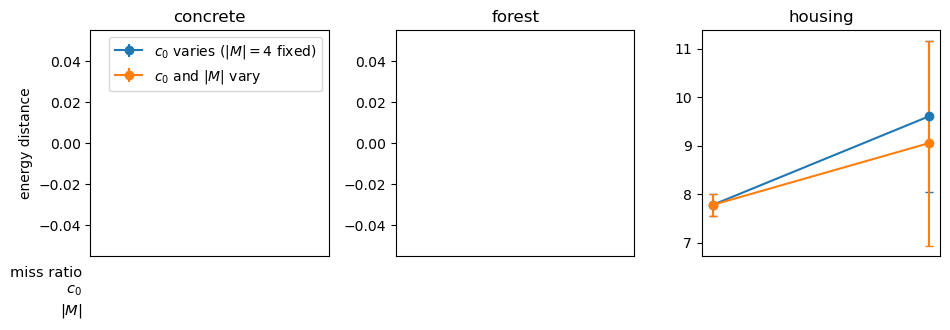

In [16]:
datasets = ["concrete", "forest", "housing"]   # your dataset names

M_BAR = 0.5

summary["miss_theory"] = (1 - summary["p"]) * M_BAR

# tick positions and labels come from the experiment where k and p vary together
exp2 = "$c_0$ and $|M|$ vary"
t = (summary[(summary.exp == exp2) & (summary.dataset == datasets[0])]
     .sort_values("miss_theory"))

xticks = t.miss_theory.values
xlabels = [f"{r:.2f}\n{p:.2f}\n{int(k)}"
           for r, p, k in zip(t.miss_theory, t.p, t.k)]

fig, axes = plt.subplots(1, len(datasets), figsize=(3.2 * len(datasets), 3.4))
axes = [axes] if len(datasets) == 1 else axes

for ax, ds in zip(axes, datasets):
    for i, exp in enumerate(experiments):
        s = summary[(summary.exp == exp) & (summary.dataset == ds)].sort_values("miss_theory")
        pdw = per_draw[(per_draw.exp == exp) & (per_draw.dataset == ds)]
        # ax.scatter(pdw.miss_theory, pdw.error, color=f"C{i}", alpha=0.25, s=12)
        ax.errorbar(s.miss_theory, s.error_mean, yerr=s.error_std, marker="o",
                    capsize=3, color=f"C{i}", label=exp)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xlabels, fontsize=10.5, linespacing=1.5)
    ax.set_title(ds)#, fontsize=9)

# row names, only on the first panel
axes[0].annotate("miss ratio\n$c_0$\n$|M|$", xy=(0, 0), xycoords="axes fraction",
                 xytext=(-6, -7), textcoords="offset points",
                 ha="right", va="top", fontsize=10.5, linespacing=1.3)
axes[0].set_ylabel("energy distance")
axes[0].legend()#fontsize=7)
fig.tight_layout()
fig.savefig("sensitivity_theory.pdf", bbox_inches="tight")
plt.show()